In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import os

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")


Libraries imported successfully!


In [6]:
file_path = "dataset/cleaned_amazon_reviews.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (21255, 19)


,Text,cleaned_review,Score,sentiment_score,sentiment_category,fear,anger,anticip,trust,surprise,positive,negative,sadness,disgust,joy,topic,cluster,pca_1,pca_2
0,I have bought several of the Vitality canned d...,i have bought several of the vitality canned d...,5,0.450000,Positive,0.000000,0.000000,0.0,0.285714,0.071429,0.285714,0.000000,0.000000,0.000000,0.285714,0,4,-0.249724,-0.060852
1,Product arrived labeled as Jumbo Salted Peanut...,product arrived labeled as jumbo salted peanut...,1,-0.033333,Negative,0.000000,0.000000,0.0,0.000000,0.000000,0.200000,0.400000,0.200000,0.000000,0.000000,3,1,-0.199094,0.044530
2,This is a confection that has been around a fe...,this is a confection that has been around a fe...,4,0.133571,Positive,0.142857,0.095238,0.0,0.119048,0.047619,0.166667,0.119048,0.071429,0.142857,0.047619,2,2,-0.164821,0.198984
3,If you are looking for the secret ingredient i...,if you are looking for the secret ingredient i...,2,0.166667,Positive,0.000000,0.000000,0.0,0.250000,0.083333,0.333333,0.000000,0.000000,0.000000,0.250000,4,0,0.119591,0.058621
4,Great taffy at a great price. There was a wid...,great taffy at a great price there was a wide ...,5,0.483333,Positive,0.000000,0.000000,0.0,0.181818,0.090909,0.272727,0.000000,0.000000,0.000000,0.181818,2,1,-0.069990,-0.043787


In [5]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Statistics:")
df.describe(include="all")


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 21255 entries, 0 to 21254
Data columns (total 19 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Text                21255 non-null  str    
 1   cleaned_review      21255 non-null  str    
 2   Score               21255 non-null  int64  
 3   sentiment_score     21255 non-null  float64
 4   sentiment_category  21255 non-null  str    
 5   fear                21255 non-null  float64
 6   anger               21255 non-null  float64
 7   anticip             21255 non-null  float64
 8   trust               21255 non-null  float64
 9   surprise            21255 non-null  float64
 10  positive            21255 non-null  float64
 11  negative            21255 non-null  float64
 12  sadness             21255 non-null  float64
 13  disgust             21255 non-null  float64
 14  joy                 21255 non-null  float64
 15  topic               21255 non-null  int64  

,Text,cleaned_review,Score,sentiment_score,sentiment_category,fear,anger,anticip,trust,surprise,positive,negative,sadness,disgust,joy,topic,cluster,pca_1,pca_2
count,21255,21255,21255.000000,21255.000000,21255,21255.000000,21255.000000,21255.0,21255.000000,21255.000000,21255.000000,21255.000000,21255.000000,21255.000000,21255.000000,21255.000000,21255.000000,2.125500e+04,2.125500e+04
unique,21255,21242,NaN,NaN,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,I have bought several of the Vitality canned d...,when we received our keurig elite for christma...,NaN,NaN,Positive,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,2,NaN,NaN,18806,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,4.172571,0.237128,NaN,0.035740,0.036447,0.0,0.138743,0.056196,0.278772,0.093606,0.043594,0.033931,0.139784,2.075982,1.919125,5.166827e-08,-1.419674e-07
std,NaN,NaN,1.306134,0.216871,NaN,0.064866,0.062576,0.0,0.101190,0.069522,0.168572,0.115759,0.066776,0.061154,0.097967,1.177849,1.279328,2.379749e-01,1.818908e-01
min,NaN,NaN,1.000000,-1.000000,NaN,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-5.776629e-01,-5.375678e-01
25%,NaN,NaN,4.000000,0.104461,NaN,0.000000,0.000000,0.0,0.076923,0.000000,0.187500,0.000000,0.000000,0.000000,0.076923,1.000000,1.000000,-1.627902e-01,-1.429703e-01
50%,NaN,NaN,5.000000,0.228120,NaN,0.000000,0.000000,0.0,0.142857,0.043478,0.255319,0.071429,0.000000,0.000000,0.142857,2.000000,2.000000,-1.715246e-02,9.225726e-03
75%,NaN,NaN,5.000000,0.366667,NaN,0.058824,0.060606,0.0,0.200000,0.093750,0.333333,0.142857,0.072727,0.055556,0.200000,3.000000,3.000000,1.782632e-01,1.449330e-01


In [7]:
print(df.columns.tolist())

['Text', 'cleaned_review', 'Score', 'sentiment_score', 'sentiment_category', 'fear', 'anger', 'anticip', 'trust', 'surprise', 'positive', 'negative', 'sadness', 'disgust', 'joy', 'topic', 'cluster', 'pca_1', 'pca_2']


In [8]:
print("Sentiment Categories:")
print(df['sentiment_category'].value_counts())

print("\nUnique Sentiments:")
print(df['sentiment_category'].unique())

print("\nMissing Values:")
print(df[['cleaned_review', 'sentiment_category']].isnull().sum())

Sentiment Categories:
sentiment_category
Positive    18806
Negative     2144
Neutral       305
Name: count, dtype: int64

Unique Sentiments:
<StringArray>
['Positive', 'Negative', 'Neutral']
Length: 3, dtype: str

Missing Values:
cleaned_review        0
sentiment_category    0
dtype: int64


In [9]:
df = df[['Text', 'cleaned_review', 'Score', 'sentiment_category']].copy()
#Removes rows where either the review or sentiment label is missing.
df = df.dropna(subset=['cleaned_review', 'sentiment_category'])
#conv to string ,lower
df['cleaned_review'] = df['cleaned_review'].astype(str)
df['sentiment_category'] = df['sentiment_category'].str.lower().str.strip()

df = df[
    df['sentiment_category'].isin(['positive', 'negative', 'neutral'])
]

print("Dataset prepared successfully!")
print("Shape:", df.shape)
print(df.head())


Dataset prepared successfully!
Shape: (21255, 4)
                                                Text  \
0  I have bought several of the Vitality canned d...   
1  Product arrived labeled as Jumbo Salted Peanut...   
2  This is a confection that has been around a fe...   
3  If you are looking for the secret ingredient i...   
4  Great taffy at a great price.  There was a wid...   

                                      cleaned_review  Score sentiment_category  
0  i have bought several of the vitality canned d...      5           positive  
1  product arrived labeled as jumbo salted peanut...      1           negative  
2  this is a confection that has been around a fe...      4           positive  
3  if you are looking for the secret ingredient i...      2           positive  
4  great taffy at a great price there was a wide ...      5           positive  


In [15]:
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Combine all cleaned reviews
all_words = ' '.join(df['cleaned_review'])

# Extract words
words = all_words.split()

# Remove common words
filtered_words = [
    word for word in words
    if word not in ENGLISH_STOP_WORDS and len(word) > 2
]

# Count word frequency
word_counts = Counter(filtered_words)

# Display top 20 words
top_words = word_counts.most_common(20)

word_frequency = pd.DataFrame(
    top_words,
    columns=['Word', 'Frequency']
)

print("Top 20 Most Frequently Used Words:")
display(word_frequency)

Top 20 Most Frequently Used Words:


,Word,Frequency
0,like,9327
1,good,7277
2,just,6261
3,coffee,6130
4,great,6081
5,taste,5823
6,product,5379
7,flavor,4853
8,love,4559
9,food,4453


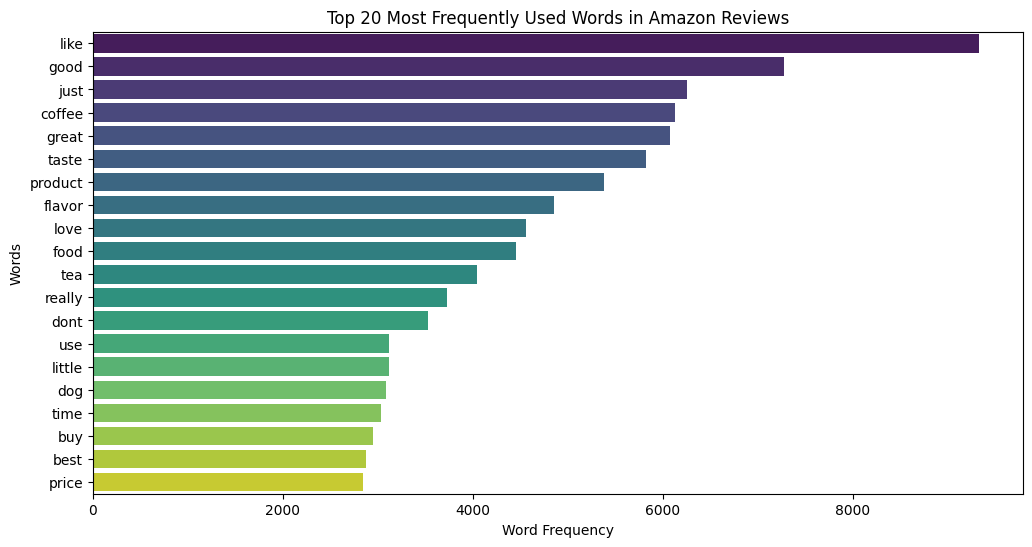

In [16]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=word_frequency,
    x='Frequency',
    y='Word',
    hue='Word',
    palette='viridis',
    legend=False
)

plt.title("Top 20 Most Frequently Used Words in Amazon Reviews")
plt.xlabel("Word Frequency")
plt.ylabel("Words")
plt.show()

In [18]:
!pip install wordcloud


Defaulting to user installation because normal site-packages is not writeable


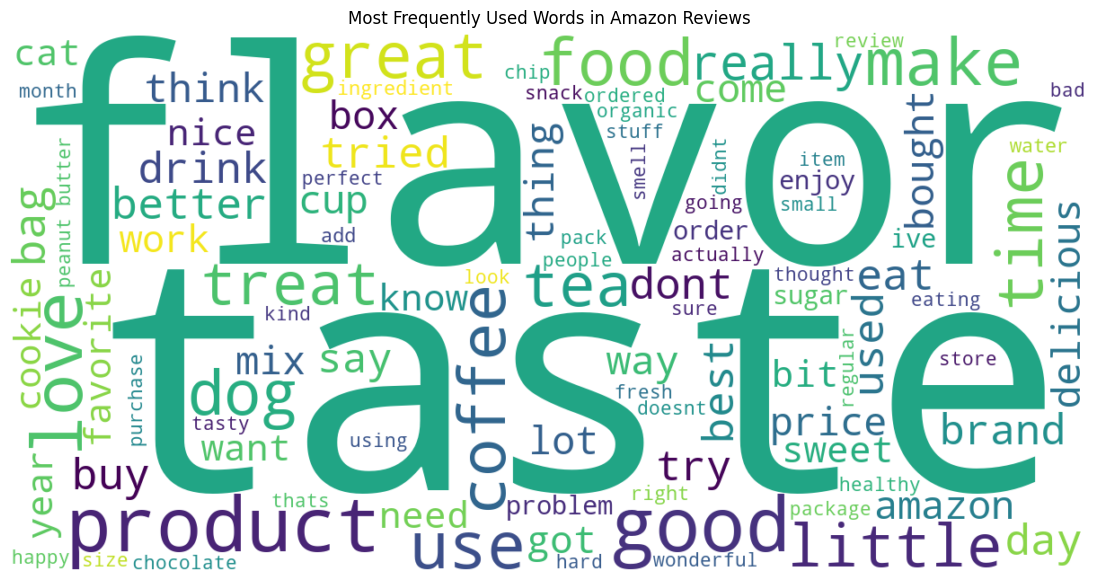

In [19]:
from wordcloud import WordCloud

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color='white',
    colormap='viridis',
    max_words=100
).generate(' '.join(filtered_words))

plt.figure(figsize=(14, 7))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title("Most Frequently Used Words in Amazon Reviews")
plt.show()


In [20]:
sentiments = ['positive', 'negative', 'neutral']

for sentiment in sentiments:

    reviews = df.loc[
        df['sentiment_category'] == sentiment,
        'cleaned_review'
    ]

    words = ' '.join(reviews).split()

    filtered = [
        word for word in words
        if word not in ENGLISH_STOP_WORDS and len(word) > 2
    ]

    counts = Counter(filtered)

    print(f"\nTop 10 Words in {sentiment.upper()} Reviews:")
    display(pd.DataFrame(
        counts.most_common(10),
        columns=['Word', 'Frequency']
    ))


Top 10 Words in POSITIVE Reviews:


,Word,Frequency
0,like,8309
1,good,7014
2,great,5979
3,coffee,5726
4,just,5628
5,taste,5257
6,product,4698
7,flavor,4475
8,love,4413
9,food,3885



Top 10 Words in NEGATIVE Reviews:


,Word,Frequency
0,like,941
1,product,620
2,just,590
3,food,547
4,taste,535
5,dog,408
6,chicken,399
7,dont,389
8,coffee,387
9,bad,371



Top 10 Words in NEUTRAL Reviews:


,Word,Frequency
0,like,77
1,product,61
2,just,43
3,dog,36
4,buy,35
5,taste,31
6,loves,28
7,eat,26
8,flavor,24
9,dont,21


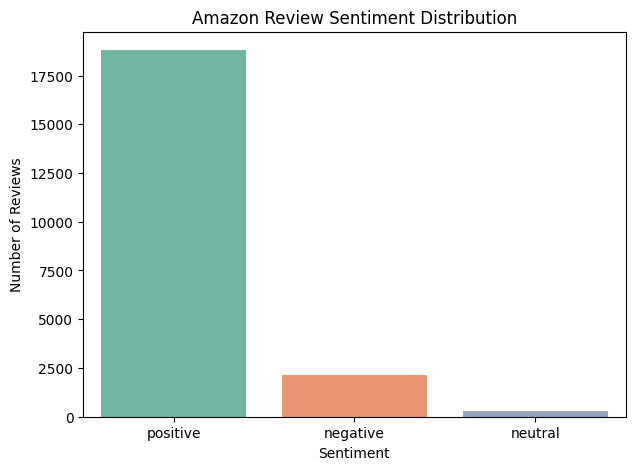

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='sentiment_category',
    hue='sentiment_category',
    order=['positive', 'negative', 'neutral'],
    palette='Set2',
    legend=False
)

plt.title("Amazon Review Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

X = df['cleaned_review']
y = df['sentiment_category']

# Split data before fitting TF-IDF
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    stop_words='english'
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF conversion completed!")
print("Training features:", X_train_tfidf.shape)
print("Testing features:", X_test_tfidf.shape)

TF-IDF conversion completed!
Training features: (17004, 5000)
Testing features: (4251, 5000)


In [12]:
from sklearn.svm import LinearSVC

model = LinearSVC(
    class_weight='balanced',
    random_state=42
)

model.fit(X_train_tfidf, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [13]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = model.predict(X_test_tfidf)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Model Accuracy: 90.52 %

Classification Report:
              precision    recall  f1-score   support

    negative       0.58      0.60      0.59       429
     neutral       0.17      0.08      0.11        61
    positive       0.95      0.95      0.95      3761

    accuracy                           0.91      4251
   macro avg       0.57      0.55      0.55      4251
weighted avg       0.90      0.91      0.90      4251



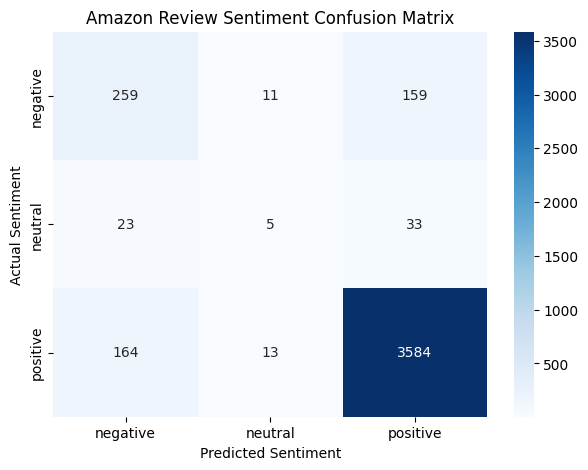

In [14]:
from sklearn.metrics import confusion_matrix

labels = ['negative', 'neutral', 'positive']

cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Amazon Review Sentiment Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.show()

In [21]:
def predict_sentiment(review):
    cleaned = re.sub(r'[^a-zA-Z\s]', '', review.lower())
    cleaned = re.sub(r'\s+', ' ', cleaned).strip()

    transformed = tfidf.transform([cleaned])
    prediction = model.predict(transformed)[0]

    return prediction

review = "This product is amazing and the quality is excellent"

print("Customer Review:", review)
print("Predicted Sentiment:", predict_sentiment(review))

Customer Review: This product is amazing and the quality is excellent
Predicted Sentiment: positive


In [22]:
results = pd.DataFrame({
    'Review': X_test.to_numpy(),
    'Actual Sentiment': y_test.to_numpy(),
    'Predicted Sentiment': y_pred
})

display(results.head(10))

,Review,Actual Sentiment,Predicted Sentiment
0,i like to mix it with muscle milk for an after...,positive,positive
1,this pancake mix is the best and easiest mix i...,positive,positive
2,just purchased one on vacation and it works as...,positive,positive
3,i love this tea seriously my mom and i suffer ...,positive,positive
4,its always wonderful to be able to give chocol...,positive,positive
5,i dont get all the hype over this coffee not m...,positive,positive
6,if you are looking for a sweetener that is del...,negative,positive
7,good price makes for nice sprouts wish it were...,positive,positive
8,my hubby considers himself a hot sauce experth...,positive,positive
9,we own a boarding kennel and often have dogs t...,positive,positive


In [23]:
from sklearn.metrics import precision_score, recall_score, f1_score

metrics = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score'],
    'Value': [
        accuracy_score(y_test, y_pred) * 100,
        precision_score(y_test, y_pred, average='weighted', zero_division=0) * 100,
        recall_score(y_test, y_pred, average='weighted', zero_division=0) * 100,
        f1_score(y_test, y_pred, average='weighted', zero_division=0) * 100
    ]
})

metrics['Value'] = metrics['Value'].round(2)

display(metrics)


,Metric,Value
0,Accuracy,90.52
1,Precision,90.08
2,Recall,90.52
3,F1 Score,90.28


In [24]:
results.to_csv('sentiment_results.csv', index=False)

metrics.to_csv('model_metrics.csv', index=False)

word_frequency.to_csv('word_frequency.csv', index=False)

print("All CSV files created successfully!")

All CSV files created successfully!


In [25]:
import joblib

joblib.dump(model, 'amazon_sentiment_model.pkl')
joblib.dump(tfidf, 'amazon_tfidf_vectorizer.pkl')

print("Model saved successfully!")

Model saved successfully!


In [26]:
print("Current folder:", os.getcwd())
print("\nFiles created:")
print(os.listdir())

Current folder: C:\Users\Ranganatha\Amazon_Product_Sentiment_Analysis

Files created:
['.ipynb_checkpoints', 'Amazon_Sentiment_Analysis.ipynb', 'amazon_sentiment_model.pkl', 'amazon_tfidf_vectorizer.pkl', 'dataset', 'model_metrics.csv', 'sentiment_results.csv', 'Untitled.ipynb', 'word_frequency.csv']
